# Orange County residents' concerns: 1989 vs. 1994

This notebook compares the two Orange County Annual Surveys. It answers: (1) how top concerns changed, (2) which demographic groups were most concerned, and (3) whether the survey year still predicts concern after demographic adjustment.

Important comparability note: the 1989 public-policy question did not include **economy** as a response option, while the 1994 question did. Therefore, crime is compared directly as a top concern; economic attitudes are compared using the shared financial-outlook questions.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

DATA_DIR = Path('.')
ZIP_1989 = DATA_DIR / 'doi_10_7280_D1KW29__v20141031.zip'
ZIP_1994 = DATA_DIR / 'doi_10_7280_D1Z594__v20141031.zip'

def read_fixed_width_from_zip(zip_path, data_name, year, specs):
    # specs use the original 1-based inclusive positions from the SPSS syntax files.
    names = list(specs)
    colspecs = [(start - 1, end) for start, end in specs.values()]
    with ZipFile(zip_path) as archive:
        with archive.open(data_name) as raw_data:
            frame = pd.read_fwf(raw_data, colspecs=colspecs, names=names, header=None)
    frame['survey_year'] = year
    return frame

specs_1989 = {
    'caseid': (1, 4), 'q4': (8, 8), 'q13': (16, 16), 'q14': (17, 17),
    'q19': (23, 23), 'q25': (29, 29), 'q71': (56, 56), 'q72': (57, 57),
    'q75': (60, 61), 'q79': (65, 65), 'q80': (66, 66), 'q90': (76, 76),
    'weight': (77, 84)
}
specs_1994 = {
    'caseid': (1, 4), 'q4': (8, 8), 'q7': (11, 11), 'q8': (12, 12),
    'q12': (16, 16), 'q13': (17, 17), 'q16': (20, 20), 'q19': (23, 23),
    'q23': (27, 27), 'q77': (81, 81), 'q78': (82, 82), 'q80': (84, 85),
    'q81': (86, 86), 'q82': (87, 87), 'q83': (88, 88), 'q94': (99, 99),
    'weight': (101, 108)
}

raw_1989 = read_fixed_width_from_zip(ZIP_1989, 'ocas89.dat', 1989, specs_1989)
raw_1994 = read_fixed_width_from_zip(ZIP_1994, 'ocas94.dat', 1994, specs_1994)
print('Loaded:', len(raw_1989), '1989 cases and', len(raw_1994), '1994 cases')

Loaded: 1085 1989 cases and 1000 1994 cases


In [2]:
# Harmonize variable names and categories across the two surveys.
top_labels_1989 = {1: 'Growth', 2: 'Traffic', 3: 'Housing', 4: 'Crime', 5: 'Schools', 6: 'Immigration', 7: 'Other'}
top_labels_1994 = {1: 'Growth', 2: 'Traffic', 3: 'Housing', 4: 'Crime', 5: 'Schools', 6: 'Immigration', 7: 'Economy', 8: 'Other'}

def harmonize_1989(df):
    out = pd.DataFrame(index=df.index)
    out['survey_year'] = 1989
    out['weight'] = pd.to_numeric(df['weight'], errors='coerce')
    out['top_concern_code'] = df['q19']
    out['top_concern'] = df['q19'].map(top_labels_1989)
    out['crime_top'] = (df['q19'] == 4).astype(float)
    out['financial_outlook'] = df['q14'].replace({8: np.nan, 9: np.nan})
    out['age_group'] = df['q71'].replace({1: '18-34', 2: '18-34', 3: '35-54', 4: '35-54', 5: '55+', 6: '55+', 9: np.nan})
    out['education'] = df['q72'].replace({1: '< HS', 2: 'HS graduate', 3: 'Some college', 4: 'College graduate', 5: np.nan, 9: np.nan})
    out['income_code'] = df['q79'].replace({8: np.nan, 9: np.nan})
    out['political_party'] = df['q80'].replace({1: 'Democrat', 2: 'Republican', 3: 'Independent/other', 4: 'Not registered', 9: np.nan})
    out['region'] = df['q75'].replace({1: 'North', 2: 'West', 3: 'Central', 4: 'South', 8: np.nan, 9: np.nan})
    out['gender'] = df['q90'].replace({1: 'Male', 2: 'Female', 9: np.nan})
    out['homeowner'] = df['q4'].replace({1: 'Owner', 2: 'Renter', 9: np.nan})
    return out

def harmonize_1994(df):
    out = pd.DataFrame(index=df.index)
    out['survey_year'] = 1994
    out['weight'] = pd.to_numeric(df['weight'], errors='coerce')
    out['top_concern_code'] = df['q16']
    out['top_concern'] = df['q16'].map(top_labels_1994)
    out['crime_top'] = (df['q16'] == 4).astype(float)
    out['financial_outlook'] = df['q8'].replace({8: np.nan, 9: np.nan})
    out['age_group'] = df['q77'].replace({1: '18-34', 2: '35-54', 3: '55+', 9: np.nan})
    out['education'] = df['q78'].replace({1: '< HS', 2: 'HS graduate', 3: 'Some college', 4: 'College graduate', 5: np.nan, 9: np.nan})
    out['income_code'] = df['q81'].replace({8: np.nan, 9: np.nan})
    out['political_party'] = df['q83'].replace({1: 'Democrat', 2: 'Republican', 3: 'Independent/other', 4: 'Not registered', 9: np.nan})
    out['region'] = df['q80'].replace({1: 'North', 2: 'West', 3: 'Central', 4: 'South', 5: 'Outside OC'})
    out['gender'] = df['q94'].replace({1: 'Male', 2: 'Female', 9: np.nan})
    out['homeowner'] = df['q4'].replace({1: 'Owner', 2: 'Renter', 9: np.nan})
    return out

survey = pd.concat([harmonize_1989(raw_1989), harmonize_1994(raw_1994)], ignore_index=True)
survey['survey_year'] = survey['survey_year'].astype('category')
survey['positive_outlook'] = (survey['financial_outlook'] == 1).astype(float)
survey.loc[survey['financial_outlook'].isna(), 'positive_outlook'] = np.nan
survey['income_group'] = survey['income_code'].map({1: 'Lower', 2: 'Lower-middle', 3: 'Middle', 4: 'Upper-middle', 5: 'Upper', 6: 'Upper', 7: 'Upper', 8: 'Upper'})
print(survey.groupby('survey_year', observed=True).size())
survey.head()

survey_year
1989    1085
1994    1000
dtype: int64


,survey_year,weight,top_concern_code,top_concern,crime_top,financial_outlook,age_group,education,income_code,political_party,region,gender,homeowner,positive_outlook,income_group
0,1989,1.0,2,Traffic,0.0,1.0,18-34,Some college,2.0,Independent/other,South,Male,Renter,1.0,Lower-middle
1,1989,1.0,4,Crime,1.0,3.0,55+,< HS,NaN,Not registered,Central,Female,Renter,0.0,NaN
2,1989,1.0,4,Crime,1.0,1.0,18-34,College graduate,7.0,Republican,North,Male,Owner,1.0,Upper
3,1989,1.0,3,Housing,0.0,3.0,35-54,College graduate,6.0,Republican,North,Male,Owner,0.0,Upper
4,1989,1.0,1,Growth,0.0,1.0,18-34,College graduate,3.0,Republican,Central,Male,Owner,1.0,Middle


## 1. How did the top concerns change?

In [3]:
def weighted_percentages(frame, group_col, value_col):
    clean = frame.dropna(subset=[group_col, value_col, 'weight']).copy()
    weighted = clean.groupby([group_col, value_col], observed=True)['weight'].sum()
    return (weighted / weighted.groupby(level=0).sum() * 100).rename('percent').reset_index()

top_table = weighted_percentages(survey, 'survey_year', 'top_concern')
display(top_table.sort_values(['survey_year', 'percent'], ascending=[True, False]))

crime_table = weighted_percentages(survey, 'survey_year', 'crime_top')
outlook_table = weighted_percentages(survey, 'survey_year', 'financial_outlook')
display(crime_table)
display(outlook_table)

,survey_year,top_concern,percent
6,1989,Traffic,41.275797
1,1989,Growth,17.073171
2,1989,Housing,13.508443
0,1989,Crime,11.257036
3,1989,Immigration,8.818011
5,1989,Schools,5.347092
4,1989,Other,2.720450
7,1994,Crime,31.111111
8,1994,Economy,18.282828
11,1994,Immigration,16.161616


,survey_year,crime_top,percent
0,1989,0.0,88.940092
1,1989,1.0,11.059908
2,1994,0.0,69.200000
3,1994,1.0,30.800000


,survey_year,financial_outlook,percent
0,1989,1.0,49.812734
1,1989,2.0,14.325843
2,1989,3.0,35.861423
3,1994,1.0,44.183565
4,1994,2.0,10.779082
5,1994,3.0,45.037353


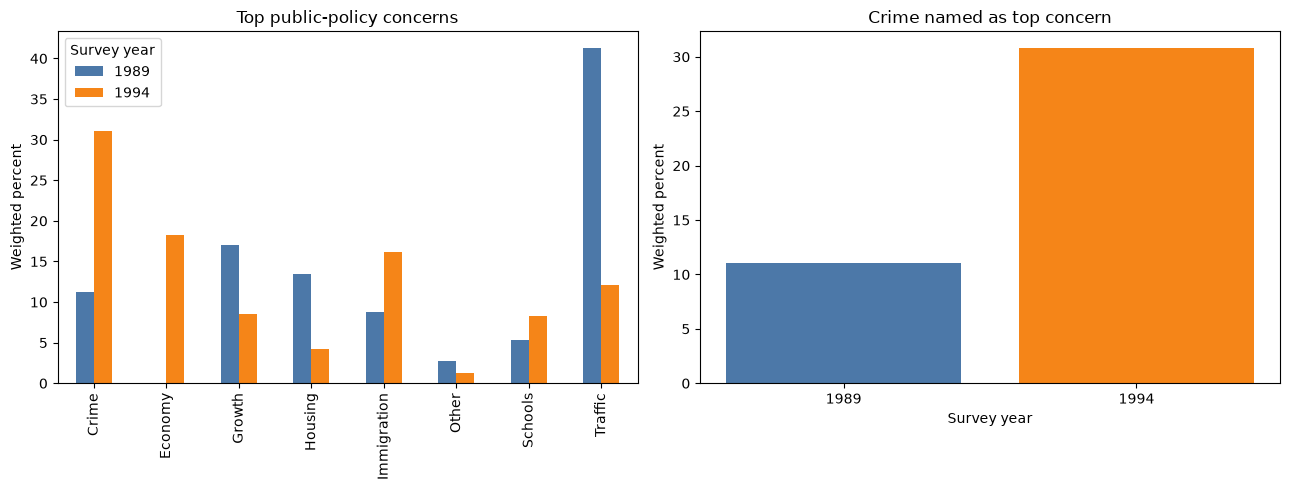

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_plot = top_table.pivot(index='top_concern', columns='survey_year', values='percent').fillna(0)
top_plot.plot.bar(ax=axes[0], color=['#4c78a8', '#f58518'])
axes[0].set(title='Top public-policy concerns', ylabel='Weighted percent', xlabel='')
axes[0].legend(title='Survey year')
crime_plot = crime_table[crime_table['crime_top'] == 1]
axes[1].bar(crime_plot['survey_year'].astype(str), crime_plot['percent'], color=['#4c78a8', '#f58518'])
axes[1].set(title='Crime named as top concern', xlabel='Survey year', ylabel='Weighted percent')
plt.tight_layout()
plt.show()

## 2. Which groups were most concerned?

The following table reports weighted crime concern by demographic group and year. The same function can be used for positive economic outlook.

In [5]:
def weighted_by_year_group(frame, group_col, value_col):
    clean = frame.dropna(subset=['survey_year', group_col, value_col, 'weight']).copy()
    weighted = clean.groupby(['survey_year', group_col, value_col], observed=True)['weight'].sum()
    denominator = weighted.groupby(level=['survey_year', group_col]).transform('sum')
    return (weighted / denominator * 100).rename('percent').reset_index()

group_variables = ['age_group', 'gender', 'income_group', 'education', 'homeowner', 'political_party', 'region']
crime_by_group = []
outlook_by_group = []
for variable in group_variables:
    crime_group = weighted_by_year_group(survey, variable, 'crime_top')
    crime_group['group_variable'] = variable
    crime_by_group.append(crime_group[crime_group['crime_top'] == 1])
    outlook_group = weighted_by_year_group(survey, variable, 'positive_outlook')
    outlook_group['group_variable'] = variable
    outlook_by_group.append(outlook_group[outlook_group['positive_outlook'] == 1])
crime_by_group = pd.concat(crime_by_group, ignore_index=True)
outlook_by_group = pd.concat(outlook_by_group, ignore_index=True)
display(crime_by_group.sort_values(['group_variable', 'survey_year', 'percent'], ascending=[True, True, False]))
display(outlook_by_group.sort_values(['group_variable', 'survey_year', 'percent'], ascending=[True, True, False]))

,survey_year,age_group,crime_top,percent,group_variable,gender,income_group,education,homeowner,political_party,region
2,1989,55+,1.0,12.452830,age_group,NaN,NaN,NaN,NaN,NaN,NaN
1,1989,35-54,1.0,11.190476,age_group,NaN,NaN,NaN,NaN,NaN,NaN
0,1989,18-34,1.0,10.000000,age_group,NaN,NaN,NaN,NaN,NaN,NaN
4,1994,35-54,1.0,32.564103,age_group,NaN,NaN,NaN,NaN,NaN,NaN
3,1994,18-34,1.0,29.863014,age_group,NaN,NaN,NaN,NaN,NaN,NaN
5,1994,55+,1.0,29.004329,age_group,NaN,NaN,NaN,NaN,NaN,NaN
19,1989,NaN,1.0,23.880597,education,NaN,NaN,< HS,NaN,NaN,NaN
22,1989,NaN,1.0,12.500000,education,NaN,NaN,Some college,NaN,NaN,NaN
21,1989,NaN,1.0,12.195122,education,NaN,NaN,HS graduate,NaN,NaN,NaN
20,1989,NaN,1.0,7.958478,education,NaN,NaN,College graduate,NaN,NaN,NaN


,survey_year,age_group,positive_outlook,percent,group_variable,gender,income_group,education,homeowner,political_party,region
0,1989,18-34,1.0,63.612565,age_group,NaN,NaN,NaN,NaN,NaN,NaN
1,1989,35-54,1.0,51.682692,age_group,NaN,NaN,NaN,NaN,NaN,NaN
2,1989,55+,1.0,26.819923,age_group,NaN,NaN,NaN,NaN,NaN,NaN
3,1994,18-34,1.0,56.321839,age_group,NaN,NaN,NaN,NaN,NaN,NaN
4,1994,35-54,1.0,45.528455,age_group,NaN,NaN,NaN,NaN,NaN,NaN
5,1994,55+,1.0,22.115385,age_group,NaN,NaN,NaN,NaN,NaN,NaN
20,1989,NaN,1.0,52.313167,education,NaN,NaN,College graduate,NaN,NaN,NaN
22,1989,NaN,1.0,50.131234,education,NaN,NaN,Some college,NaN,NaN,NaN
21,1989,NaN,1.0,49.753695,education,NaN,NaN,HS graduate,NaN,NaN,NaN
19,1989,NaN,1.0,34.375000,education,NaN,NaN,< HS,NaN,NaN,NaN


## 3. Do demographic gaps widen or narrow?

The interaction models test whether the relationship between each demographic variable and concern changes between 1989 and 1994. A small interaction p-value indicates that the gap changed across years.

In [6]:
import warnings
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
warnings.filterwarnings('ignore', category=SingularMatrixWarning)
warnings.filterwarnings('ignore', message='overflow encountered in exp', category=RuntimeWarning)
interaction_results = []
for variable in group_variables:
    model_data = survey.dropna(subset=['crime_top', 'weight', 'survey_year', variable]).copy()
    formula = f'crime_top ~ C(survey_year) * C({variable})'
    model = smf.glm(formula, data=model_data, family=sm.families.Binomial(), freq_weights=model_data['weight']).fit()
    interaction_p = model.pvalues[model.pvalues.index.str.contains(':')]
    interaction_results.append({'variable': variable, 'smallest_interaction_p': interaction_p.min() if len(interaction_p) else np.nan, 'n': len(model_data)})
interaction_results = pd.DataFrame(interaction_results).sort_values('smallest_interaction_p')
display(interaction_results)

,variable,smallest_interaction_p,n
3,education,0.010245,1783
5,political_party,0.039221,2041
6,region,0.154198,2085
1,gender,0.265445,2085
0,age_group,0.355062,2061
2,income_group,0.449910,1799
4,homeowner,0.790484,2065


## 4. Does survey year predict concern after adjustment?

The adjusted model includes all available harmonized demographic controls. The coefficient for 1994 estimates the remaining year difference, holding those characteristics constant.

In [7]:
import warnings
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
warnings.filterwarnings('ignore', category=SingularMatrixWarning)
warnings.filterwarnings('ignore', message='overflow encountered in exp', category=RuntimeWarning)
adjustment_variables = ['age_group', 'gender', 'income_group', 'education', 'homeowner', 'political_party', 'region']
model_data = survey.dropna(subset=['crime_top', 'weight', 'survey_year'] + adjustment_variables).copy()
adjustment_formula = 'crime_top ~ C(survey_year) + ' + ' + '.join(f'C({v})' for v in adjustment_variables)
adjusted_crime_model = smf.glm(adjustment_formula, data=model_data, family=sm.families.Binomial(), freq_weights=model_data['weight']).fit()
print(adjusted_crime_model.summary())

outlook_data = survey.dropna(subset=['positive_outlook', 'weight', 'survey_year'] + adjustment_variables).copy()
adjusted_outlook_model = smf.glm(adjustment_formula.replace('crime_top', 'positive_outlook'), data=outlook_data, family=sm.families.Binomial(), freq_weights=outlook_data['weight']).fit()
print(adjusted_outlook_model.summary())

def coefficient_table(model):
    result = pd.DataFrame({
        'coefficient': model.params,
        'odds_ratio': np.exp(model.params),
        'lower_95_percent': np.exp(model.conf_int()[0]),
        'upper_95_percent': np.exp(model.conf_int()[1]),
        'p_value': model.pvalues
    })
    return result.round(3)

print('Adjusted crime model coefficients and odds ratios')
display(coefficient_table(adjusted_crime_model))
print('Adjusted positive-financial-outlook model coefficients and odds ratios')
display(coefficient_table(adjusted_outlook_model))

                 Generalized Linear Model Regression Results                  
Dep. Variable:              crime_top   No. Observations:                 1514
Model:                            GLM   Df Residuals:                     1495
Model Family:                Binomial   Df Model:                           18
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -703.17
Date:                Mon, 26 Oct 2026   Deviance:                       1406.3
Time:                        23:21:56   Pearson chi2:                 1.51e+03
No. Iterations:                     5   Pseudo R-squ. (CS):            0.07980
Covariance Type:            nonrobust                                         
                                              coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

,coefficient,odds_ratio,lower_95_percent,upper_95_percent,p_value
Intercept,-2.003,0.135,0.068,0.270,0.000
C(survey_year)[T.1994],1.246,3.478,2.558,4.729,0.000
C(age_group)[T.35-54],0.261,1.298,0.952,1.769,0.099
C(age_group)[T.55+],0.233,1.262,0.859,1.854,0.236
C(gender)[T.Male],0.238,1.269,0.971,1.658,0.081
C(income_group)[T.Lower-middle],0.132,1.141,0.763,1.707,0.520
C(income_group)[T.Middle],0.254,1.289,0.867,1.918,0.210
C(income_group)[T.Upper],-0.149,0.861,0.434,1.710,0.670
C(income_group)[T.Upper-middle],0.426,1.532,0.973,2.411,0.065
C(education)[T.College graduate],-0.643,0.526,0.306,0.905,0.020


Adjusted positive-financial-outlook model coefficients and odds ratios


,coefficient,odds_ratio,lower_95_percent,upper_95_percent,p_value
Intercept,-0.158,0.854,0.469,1.554,0.605
C(survey_year)[T.1994],0.101,1.106,0.868,1.410,0.414
C(age_group)[T.35-54],-0.540,0.583,0.454,0.748,0.000
C(age_group)[T.55+],-1.304,0.271,0.195,0.377,0.000
C(gender)[T.Male],0.107,1.113,0.893,1.388,0.341
C(income_group)[T.Lower-middle],0.044,1.045,0.742,1.472,0.801
C(income_group)[T.Middle],0.358,1.431,1.022,2.002,0.037
C(income_group)[T.Upper],1.188,3.281,2.060,5.226,0.000
C(income_group)[T.Upper-middle],0.499,1.647,1.117,2.427,0.012
C(education)[T.College graduate],0.013,1.013,0.619,1.657,0.960


# Summary of findings

The two surveys show a clear change in what Orange County residents saw as the biggest problem. In 1989, traffic was the top concern (about 41%), followed by growth (17%), housing (14%), and crime (11%). By 1994, crime had become the top concern (about 31%), followed by the economy (18%) and immigration (16%). Traffic fell to about 12%.

Crime concern increased by about 20 percentage points. The share naming crime as the top concern was about three times higher in 1994 than in 1989. This suggests that the change was not just caused by small demographic differences between the samples.

The economic results need to be interpreted carefully. The 1989 survey did not include economy as a top-concern response, so economy cannot be compared directly as a top concern. Using the shared financial-outlook question, about 50% of respondents in 1989 expected to be better off, compared with about 44% in 1994. The share expecting to stay about the same increased from about 36% to 45%. This suggests that economic optimism weakened somewhat, although the adjusted year difference was not statistically strong.

Crime concern was higher in 1994 across nearly every group. In 1994, concern was relatively high among people ages 35–54, men, people with a high-school education, upper-middle-income respondents, Republicans, renters, and people in the Central or West regions. In 1989, the differences between groups were much smaller.

The interaction tests ask whether demographic gaps changed between the two surveys. Education showed the clearest evidence that the gap changed over time. The interactions for age, gender, income, homeownership, political party, and region were not strong enough to conclude that their gaps changed reliably.

After controlling for the demographic variables, survey year still strongly predicted crime concern. The estimated odds of naming crime as the top concern were about 3.4 times higher in 1994 than in 1989. This supports the conclusion that public opinion itself shifted toward crime, rather than the increase being explained only by who was surveyed.

For positive financial outlook, the adjusted year effect was small and not statistically significant. Income was more important: middle-, upper-middle-, and upper-income respondents were more likely than lower-income respondents to expect a positive financial future.

Overall, Orange County’s concerns changed from traffic, growth, and housing in 1989 toward crime, the economy, and immigration in 1994. Crime became much more important, and that shift remained after demographic adjustment. Economic optimism was somewhat lower in 1994, but the evidence for a year effect was weaker. These results compare two cross-sectional surveys; they do not follow the same individuals over time.